In [1]:
import numpy as np
import scipy
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
import lattice
import importlib
import kmc
import loading as ld
importlib.reload(kmc)

<module 'kmc' from '/home/nara/Projetos/programa-tiago/kmc.py'>

In [2]:
import shutil
import os
pasta = 'dados_krot'
try: 
    shutil.rmtree(pasta)
except:
    pass

os.makedirs(pasta)

In [2]:
# Parâmetros 1D

RF=1
F=1
tau = 1
r0=1
n=50
L =  r0*np.array([n])
PBC = [0]
LOAD_FIXED_KAPPA= False
FIXED_KAPPA = 0.476#2/3
save = False
cutoff = r0

nrounds = 3000

KF = (RF/r0)**6/tau

In [ ]:

krot_dip= np.linspace(0,1200,50)*KF
kappas2_LD = []
for i in range(len(krot_dip)):
    krot_i = krot_dip[i]
    syst = ld.System(save=save,RF=RF,tau=tau,r0=r0,cutoff=cutoff,L=L,LOAD_FIXED_KAPPA=LOAD_FIXED_KAPPA,FIXED_KAPPA=FIXED_KAPPA,n=n,PBC=PBC,krot_dip=krot_i)
    syst.make_lattice()
    
    results = Parallel(n_jobs=7,verbose=2)(delayed(kmc.kmc_run_fluor)(syst) for n in range(nrounds))
    out_dict = kmc.process_results(results,file_header="",dim=len(L),RF=RF,tau=tau,r0=r0,FIXED_KAPPA=FIXED_KAPPA)
    kappas2_LD.append(out_dict['kappa2_LD'])

np.savetxt(f"{pasta}/kappas2_Krot_1D_1.txt", kappas2_LD)

/tmp/ipykernel_116686/1981992008.py:25: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(fontsize=13)


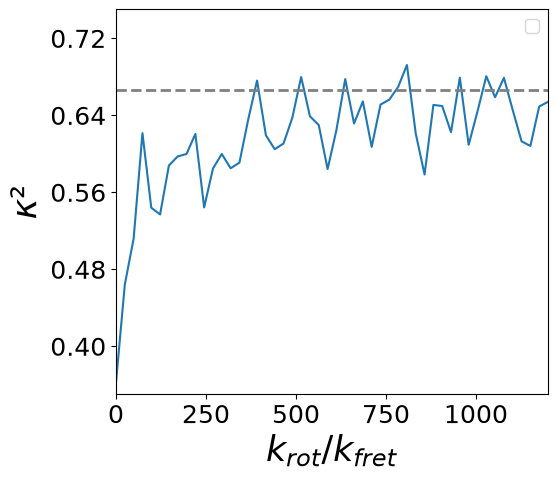

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

krot_dip= np.linspace(0,1200,50)*KF
c = np.loadtxt(f"dados_krot/kappas2_Krot_1D_1.txt")
#dados2 = np.loadtxt("kappas2_Krot_1D_2.txt")

plt.figure(figsize = (6,5))
plt.plot(krot_dip, c)
plt.xlabel(r"$k_{rot}/k_{fret}$", fontsize = 25)
plt.ylabel(r"$\kappa²$", fontsize = 25)

plt.xticks(fontsize=18)
plt.yticks(fontsize=18)


plt.xlim(0,1200)
plt.ylim(0.35,0.75)
plt.tight_layout()
plt.axhline(2/3, linestyle = '--', c = 'gray', linewidth = 2)
plt.gca().xaxis.set_major_locator(MaxNLocator(5))
plt.gca().yaxis.set_major_locator(MaxNLocator(5))

plt.legend(fontsize=13)
plt.savefig('graf_krot.png', dpi = 400)
plt.show()

